In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("Documents/NASA/train_FD001_descriptive.csv")
df.head()

,engine,cycle,op_setting_1,op_setting_2,op_setting_3,Fan inlet temperature (°R),LPC outlet temperature (°R),HPC outlet temperature (°R),LPT outlet temperature (°R),Fan inlet Pressure (psia),...,Corrected fan speed (rpm),Corrected core speed (rpm),Bypass Ratio,Burner fuel-air ratio,Bleed Enthalpy,Required fan speed,Required fan conversion speed,High-pressure turbines Cool air flow,Low-pressure turbines Cool air flow,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


In [3]:
df.columns

Index(['engine', 'cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3',
       'Fan inlet temperature (°R)', 'LPC outlet temperature (°R)',
       'HPC outlet temperature (°R)', 'LPT outlet temperature (°R)',
       'Fan inlet Pressure (psia)', 'bypass-duct pressure (psia)',
       'HPC outlet pressure (psia)', 'Physical fan speed (rpm)',
       'Physical core speed (rpm)', 'Engine pressure ratio (P50/P2)',
       'HPC outlet Static pressure (psia)',
       'Ratio of fuel flow to Ps30 (pps/psia)', 'Corrected fan speed (rpm)',
       'Corrected core speed (rpm)', 'Bypass Ratio', 'Burner fuel-air ratio',
       'Bleed Enthalpy', 'Required fan speed', 'Required fan conversion speed',
       'High-pressure turbines Cool air flow',
       'Low-pressure turbines Cool air flow', 'RUL'],
      dtype='object')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 27 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   engine                                 20631 non-null  int64  
 1   cycle                                  20631 non-null  int64  
 2   op_setting_1                           20631 non-null  float64
 3   op_setting_2                           20631 non-null  float64
 4   op_setting_3                           20631 non-null  float64
 5   Fan inlet temperature (°R)             20631 non-null  float64
 6   LPC outlet temperature (°R)            20631 non-null  float64
 7   HPC outlet temperature (°R)            20631 non-null  float64
 8   LPT outlet temperature (°R)            20631 non-null  float64
 9   Fan inlet Pressure (psia)              20631 non-null  float64
 10  bypass-duct pressure (psia)            20631 non-null  float64
 11  HP

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
duplicate = df[df.duplicated(subset=["engine","cycle"], keep=False)]
duplicate

,engine,cycle,op_setting_1,op_setting_2,op_setting_3,Fan inlet temperature (°R),LPC outlet temperature (°R),HPC outlet temperature (°R),LPT outlet temperature (°R),Fan inlet Pressure (psia),...,Corrected fan speed (rpm),Corrected core speed (rpm),Bypass Ratio,Burner fuel-air ratio,Bleed Enthalpy,Required fan speed,Required fan conversion speed,High-pressure turbines Cool air flow,Low-pressure turbines Cool air flow,RUL


In [7]:
engine_1 = df[df["engine"]==1]
engine_1

,engine,cycle,op_setting_1,op_setting_2,op_setting_3,Fan inlet temperature (°R),LPC outlet temperature (°R),HPC outlet temperature (°R),LPT outlet temperature (°R),Fan inlet Pressure (psia),...,Corrected fan speed (rpm),Corrected core speed (rpm),Bypass Ratio,Burner fuel-air ratio,Bleed Enthalpy,Required fan speed,Required fan conversion speed,High-pressure turbines Cool air flow,Low-pressure turbines Cool air flow,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187,1,188,-0.0067,0.0003,100.0,518.67,643.75,1602.38,1422.78,14.62,...,2388.23,8117.69,8.5207,0.03,396,2388,100.0,38.51,22.9588,4
188,1,189,-0.0006,0.0002,100.0,518.67,644.18,1596.17,1428.01,14.62,...,2388.33,8117.51,8.5183,0.03,395,2388,100.0,38.48,23.1127,3
189,1,190,-0.0027,0.0001,100.0,518.67,643.64,1599.22,1425.95,14.62,...,2388.35,8112.58,8.5223,0.03,398,2388,100.0,38.49,23.0675,2
190,1,191,-0.0000,-0.0004,100.0,518.67,643.34,1602.36,1425.77,14.62,...,2388.30,8114.61,8.5174,0.03,394,2388,100.0,38.45,23.1295,1


In [8]:
group_engine = df.groupby("engine")["cycle"].max()
group_engine

engine
1      192
2      287
3      179
4      189
5      269
      ... 
96     336
97     202
98     156
99     185
100    200
Name: cycle, Length: 100, dtype: int64

In [9]:
group_engine.describe()

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

In [10]:
df.describe()

,engine,cycle,op_setting_1,op_setting_2,op_setting_3,Fan inlet temperature (°R),LPC outlet temperature (°R),HPC outlet temperature (°R),LPT outlet temperature (°R),Fan inlet Pressure (psia),...,Corrected fan speed (rpm),Corrected core speed (rpm),Bypass Ratio,Burner fuel-air ratio,Bleed Enthalpy,Required fan speed,Required fan conversion speed,High-pressure turbines Cool air flow,Low-pressure turbines Cool air flow,RUL
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,2.063100e+04,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,5.186700e+02,642.680934,1590.523119,1408.933782,1.462000e+01,...,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705,107.807862
std,29.227633,68.880990,0.002187,0.000293,0.0,6.537152e-11,0.500053,6.131150,9.000605,3.394700e-12,...,0.071919,19.076176,0.037505,1.556432e-14,1.548763,0.0,0.0,0.180746,0.108251,68.880990
min,1.000000,1.000000,-0.008700,-0.000600,100.0,5.186700e+02,641.210000,1571.040000,1382.250000,1.462000e+01,...,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200,0.000000
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,5.186700e+02,642.325000,1586.260000,1402.360000,1.462000e+01,...,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800,51.000000
50%,52.000000,104.000000,0.000000,0.000000,100.0,5.186700e+02,642.640000,1590.100000,1408.040000,1.462000e+01,...,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900,103.000000
75%,77.000000,156.000000,0.001500,0.000300,100.0,5.186700e+02,643.000000,1594.380000,1414.555000,1.462000e+01,...,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800,155.000000
max,100.000000,362.000000,0.008700,0.000600,100.0,5.186700e+02,644.530000,1616.910000,1441.490000,1.462000e+01,...,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400,361.000000


In [11]:
df["engine"].nunique()

100

In [12]:
df.shape

(20631, 27)

In [13]:
df.isnull().sum()

engine                                   0
cycle                                    0
op_setting_1                             0
op_setting_2                             0
op_setting_3                             0
Fan inlet temperature (°R)               0
LPC outlet temperature (°R)              0
HPC outlet temperature (°R)              0
LPT outlet temperature (°R)              0
Fan inlet Pressure (psia)                0
bypass-duct pressure (psia)              0
HPC outlet pressure (psia)               0
Physical fan speed (rpm)                 0
Physical core speed (rpm)                0
Engine pressure ratio (P50/P2)           0
HPC outlet Static pressure (psia)        0
Ratio of fuel flow to Ps30 (pps/psia)    0
Corrected fan speed (rpm)                0
Corrected core speed (rpm)               0
Bypass Ratio                             0
Burner fuel-air ratio                    0
Bleed Enthalpy                           0
Required fan speed                       0
Required fa

In [14]:
df["cycle"].describe()

count    20631.000000
mean       108.807862
std         68.880990
min          1.000000
25%         52.000000
50%        104.000000
75%        156.000000
max        362.000000
Name: cycle, dtype: float64

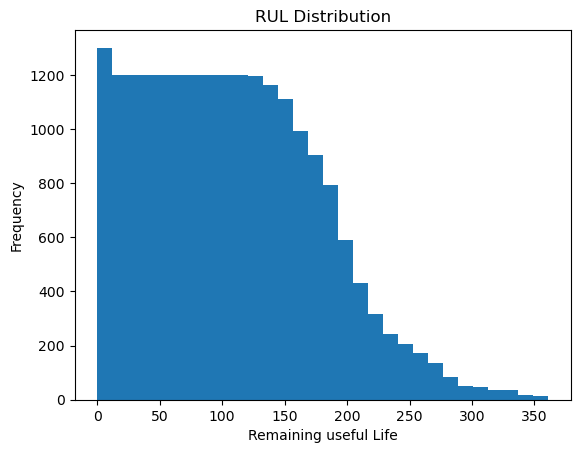

In [15]:
plt.hist(df["RUL"], bins=30)
plt.xlabel("Remaining useful Life")
plt.ylabel("Frequency")
plt.title("RUL Distribution")
plt.show()

In [16]:
sensor = "LPC outlet temperature (°R)"

In [17]:
df[sensor]

0        641.82
1        642.15
2        642.35
3        642.35
4        642.37
          ...  
20626    643.49
20627    643.54
20628    643.42
20629    643.23
20630    643.85
Name: LPC outlet temperature (°R), Length: 20631, dtype: float64

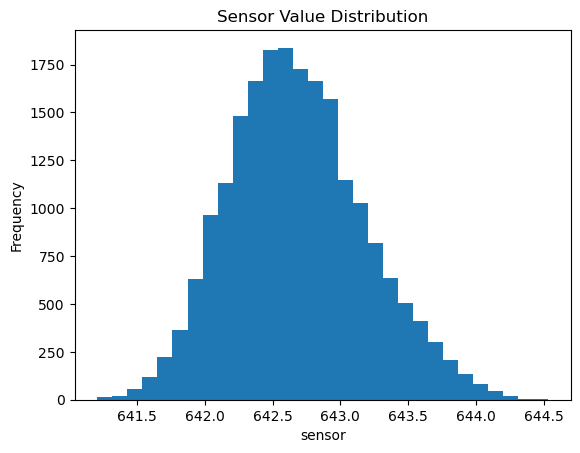

In [18]:
plt.hist(df[sensor], bins=30)
plt.xlabel("sensor")
plt.ylabel("Frequency")
plt.title("Sensor Value Distribution")
plt.show()

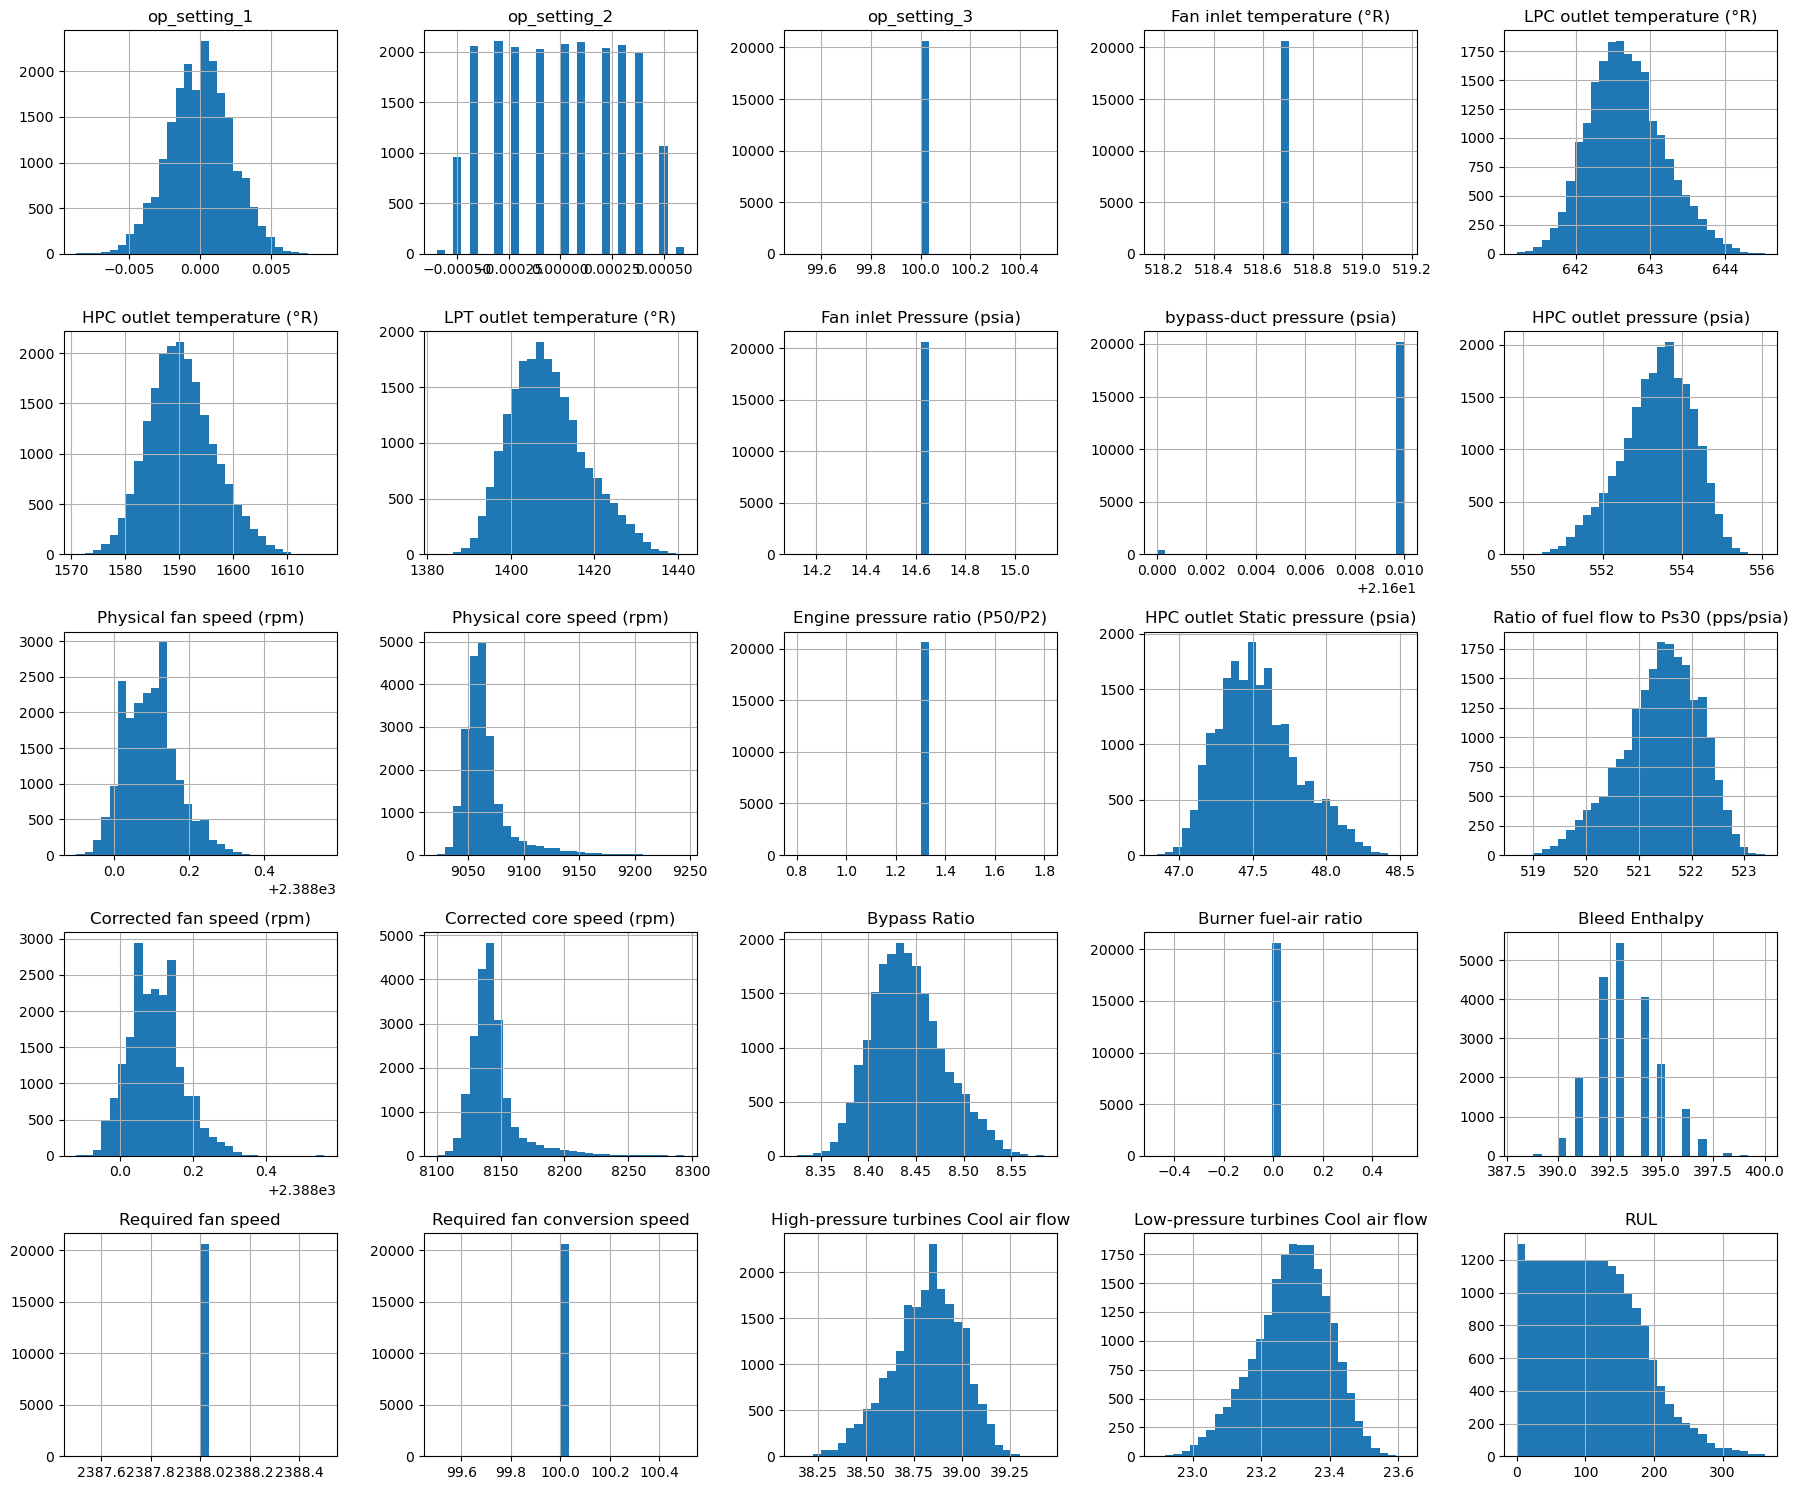

In [19]:
cols = df.columns.drop(["engine", "cycle"])
df[cols].hist(bins=30, figsize =(18, 15))
plt.tight_layout()
plt.show()

In [20]:
df.std(numeric_only = True).sort_values()

op_setting_3                             0.000000e+00
Required fan speed                       0.000000e+00
Required fan conversion speed            0.000000e+00
Burner fuel-air ratio                    1.556432e-14
Engine pressure ratio (P50/P2)           4.660829e-13
Fan inlet Pressure (psia)                3.394700e-12
Fan inlet temperature (°R)               6.537152e-11
op_setting_2                             2.930621e-04
bypass-duct pressure (psia)              1.388985e-03
op_setting_1                             2.187313e-03
Bypass Ratio                             3.750504e-02
Physical fan speed (rpm)                 7.098548e-02
Corrected fan speed (rpm)                7.191892e-02
Low-pressure turbines Cool air flow      1.082509e-01
High-pressure turbines Cool air flow     1.807464e-01
HPC outlet Static pressure (psia)        2.670874e-01
LPC outlet temperature (°R)              5.000533e-01
Ratio of fuel flow to Ps30 (pps/psia)    7.375534e-01
HPC outlet pressure (psia)  

In [21]:
drop_cols = [
    "op_setting_3",
    "Required fan speed",
    "Required fan conversion speed",
    "Burner fuel-air ratio",
    "Engine pressure ratio (P50/P2)",
    "Fan inlet temperature (°R)",
    "Fan inlet Pressure (psia)",
    "bypass-duct pressure (psia)"
]
df_clean = df.drop(columns = drop_cols)
df_clean.shape

(20631, 19)

In [22]:
df_clean

,engine,cycle,op_setting_1,op_setting_2,LPC outlet temperature (°R),HPC outlet temperature (°R),LPT outlet temperature (°R),HPC outlet pressure (psia),Physical fan speed (rpm),Physical core speed (rpm),HPC outlet Static pressure (psia),Ratio of fuel flow to Ps30 (pps/psia),Corrected fan speed (rpm),Corrected core speed (rpm),Bypass Ratio,Bleed Enthalpy,High-pressure turbines Cool air flow,Low-pressure turbines Cool air flow,RUL
0,1,1,-0.0007,-0.0004,641.82,1589.70,1400.60,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190,191
1,1,2,0.0019,-0.0003,642.15,1591.82,1403.14,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236,190
2,1,3,-0.0043,0.0003,642.35,1587.99,1404.20,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442,189
3,1,4,0.0007,0.0000,642.35,1582.79,1401.87,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,642.37,1582.85,1406.22,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044,187
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,-0.0004,-0.0003,643.49,1597.98,1428.63,551.43,2388.19,9065.52,48.07,519.49,2388.26,8137.60,8.4956,397,38.49,22.9735,4
20627,100,197,-0.0016,-0.0005,643.54,1604.50,1433.58,550.86,2388.23,9065.11,48.04,519.68,2388.22,8136.50,8.5139,395,38.30,23.1594,3
20628,100,198,0.0004,0.0000,643.42,1602.46,1428.18,550.94,2388.24,9065.90,48.09,520.01,2388.24,8141.05,8.5646,398,38.44,22.9333,2
20629,100,199,-0.0011,0.0003,643.23,1605.26,1426.53,550.68,2388.25,9073.72,48.39,519.67,2388.23,8139.29,8.5389,395,38.29,23.0640,1


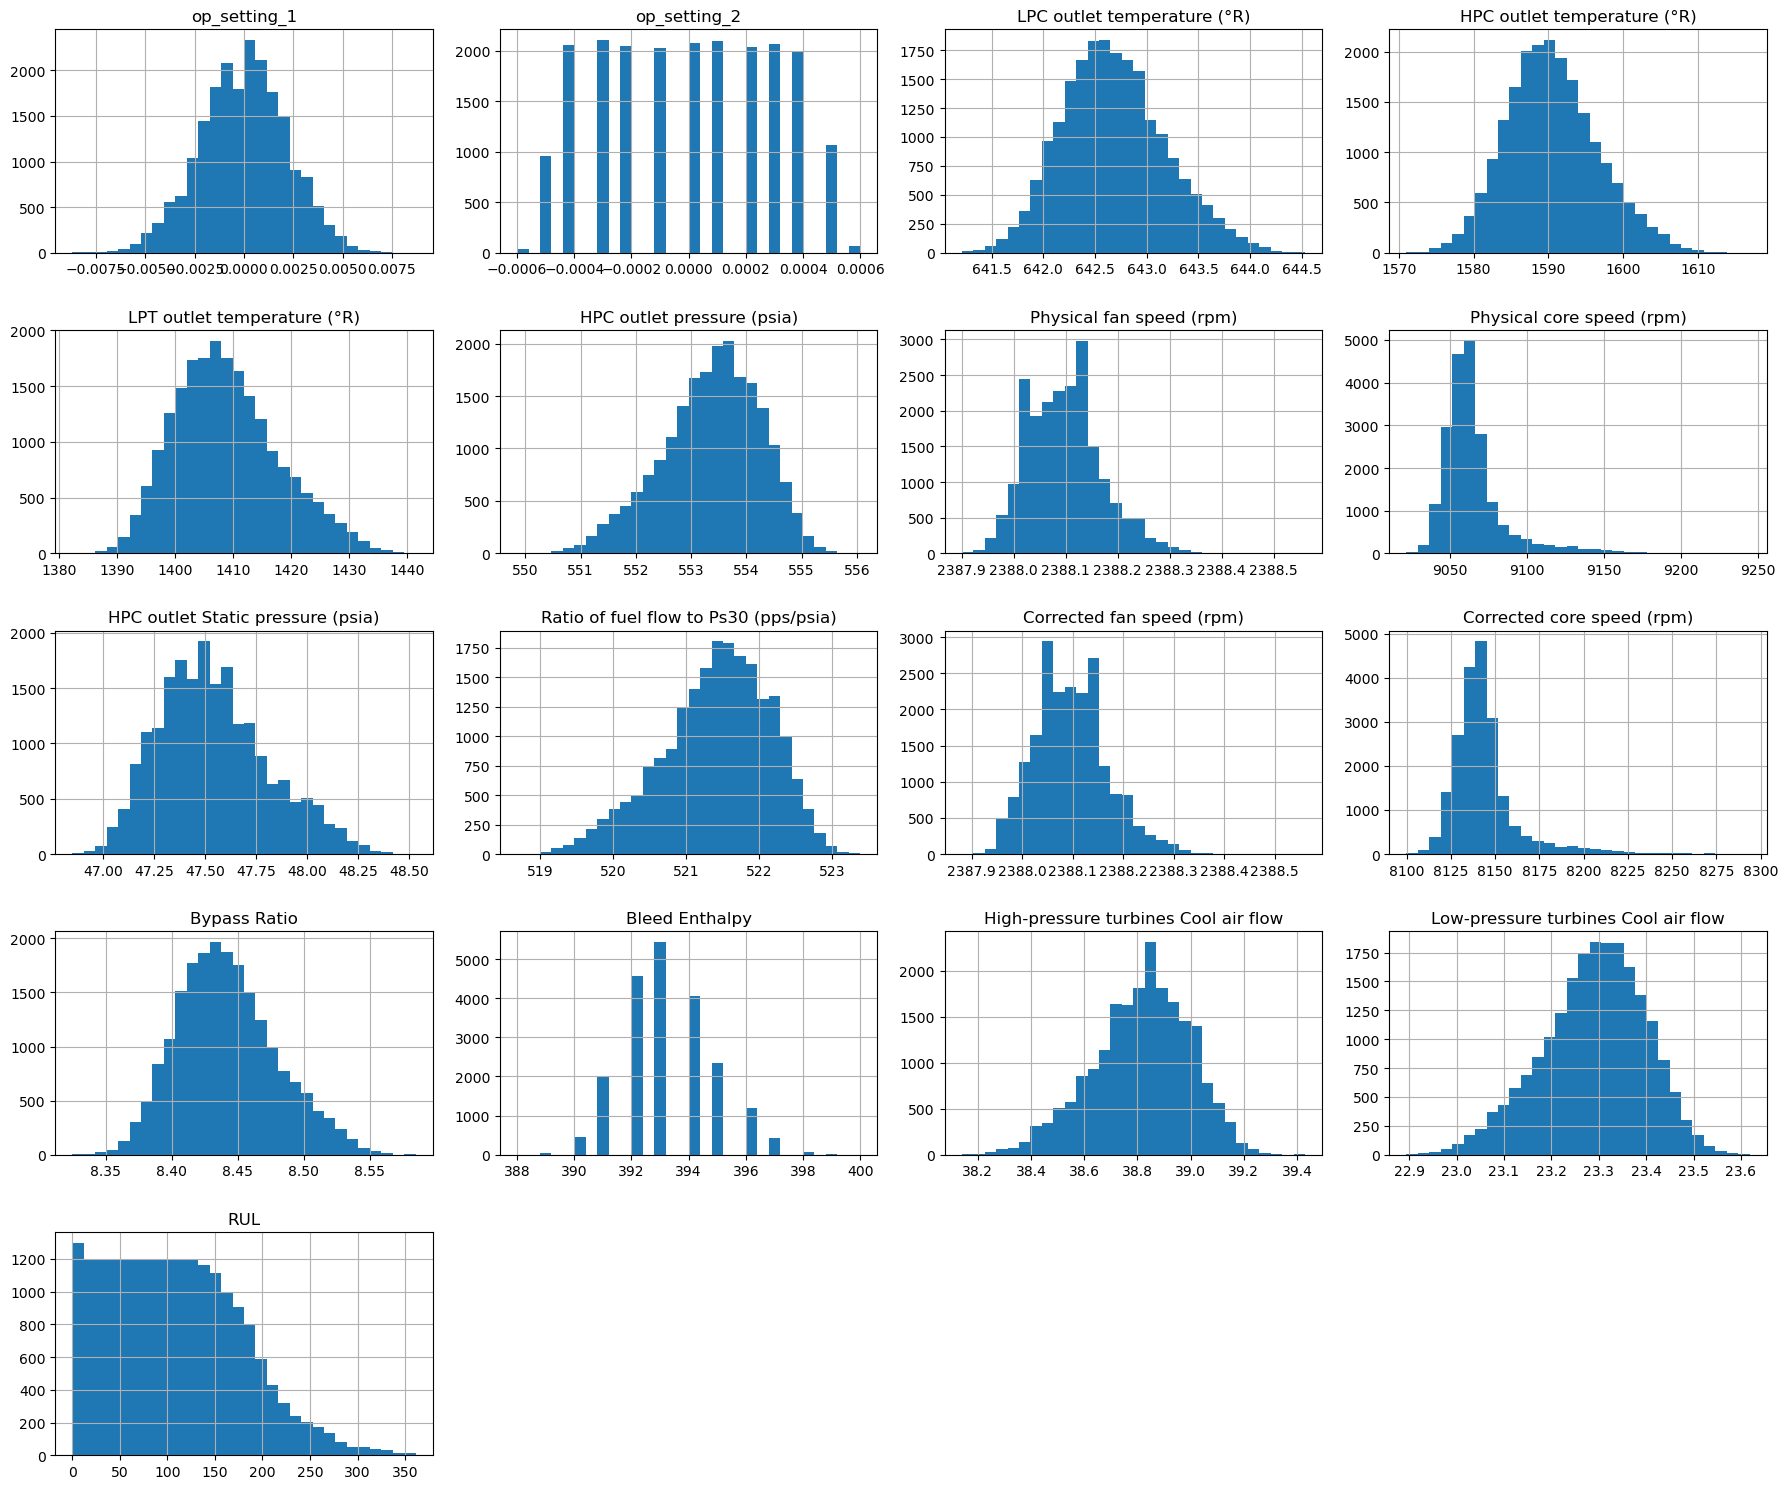

In [23]:
cols = df_clean.columns.drop(["engine", "cycle"])
df[cols].hist(bins=30, figsize =(18, 15))
plt.tight_layout()
plt.show()

In [24]:
df_clean.describe()

,engine,cycle,op_setting_1,op_setting_2,LPC outlet temperature (°R),HPC outlet temperature (°R),LPT outlet temperature (°R),HPC outlet pressure (psia),Physical fan speed (rpm),Physical core speed (rpm),HPC outlet Static pressure (psia),Ratio of fuel flow to Ps30 (pps/psia),Corrected fan speed (rpm),Corrected core speed (rpm),Bypass Ratio,Bleed Enthalpy,High-pressure turbines Cool air flow,Low-pressure turbines Cool air flow,RUL
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,642.680934,1590.523119,1408.933782,553.367711,2388.096652,9065.242941,47.541168,521.413470,2388.096152,8143.752722,8.442146,393.210654,38.816271,23.289705,107.807862
std,29.227633,68.880990,0.002187,0.000293,0.500053,6.131150,9.000605,0.885092,0.070985,22.082880,0.267087,0.737553,0.071919,19.076176,0.037505,1.548763,0.180746,0.108251,68.880990
min,1.000000,1.000000,-0.008700,-0.000600,641.210000,1571.040000,1382.250000,549.850000,2387.900000,9021.730000,46.850000,518.690000,2387.880000,8099.940000,8.324900,388.000000,38.140000,22.894200,0.000000
25%,26.000000,52.000000,-0.001500,-0.000200,642.325000,1586.260000,1402.360000,552.810000,2388.050000,9053.100000,47.350000,520.960000,2388.040000,8133.245000,8.414900,392.000000,38.700000,23.221800,51.000000
50%,52.000000,104.000000,0.000000,0.000000,642.640000,1590.100000,1408.040000,553.440000,2388.090000,9060.660000,47.510000,521.480000,2388.090000,8140.540000,8.438900,393.000000,38.830000,23.297900,103.000000
75%,77.000000,156.000000,0.001500,0.000300,643.000000,1594.380000,1414.555000,554.010000,2388.140000,9069.420000,47.700000,521.950000,2388.140000,8148.310000,8.465600,394.000000,38.950000,23.366800,155.000000
max,100.000000,362.000000,0.008700,0.000600,644.530000,1616.910000,1441.490000,556.060000,2388.560000,9244.590000,48.530000,523.380000,2388.560000,8293.720000,8.584800,400.000000,39.430000,23.618400,361.000000


In [25]:
Max = 9244.590000
mean = 9065.242941
std = 22.082880
Min = 9021.730000
diff_max_phy = ( Max - mean) / std
diff_min_phy = ( mean - Min) / std
print(diff_max_phy)
print(diff_min_phy)

8.121542978089801
1.9704377780434827


In [26]:
Max = 8293.720000	
mean = 8143.752722	
std = 19.076176
Min = 8099.940000
diff_max_cor = ( Max - mean) / std
diff_min_cor = ( mean - Min) / std
print(diff_max_cor)
print(diff_min_cor)

7.861495825997787
2.296724563665201


In [27]:
engine_1 = df_clean[df_clean["engine"]==1]

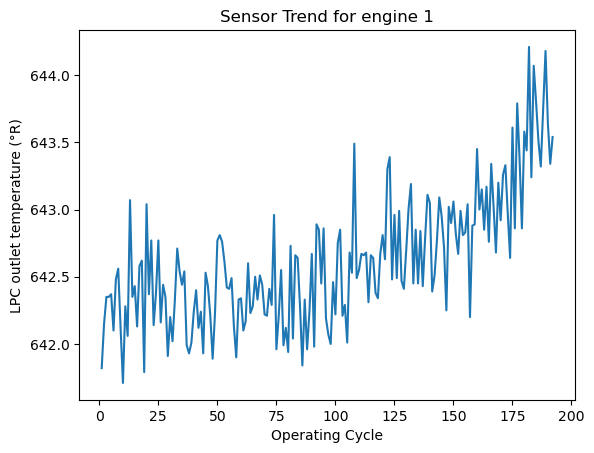

In [28]:
plt.plot(engine_1["cycle"], engine_1[sensor])
plt.xlabel("Operating Cycle")
plt.ylabel(sensor)
plt.title("Sensor Trend for engine 1")
plt.show()

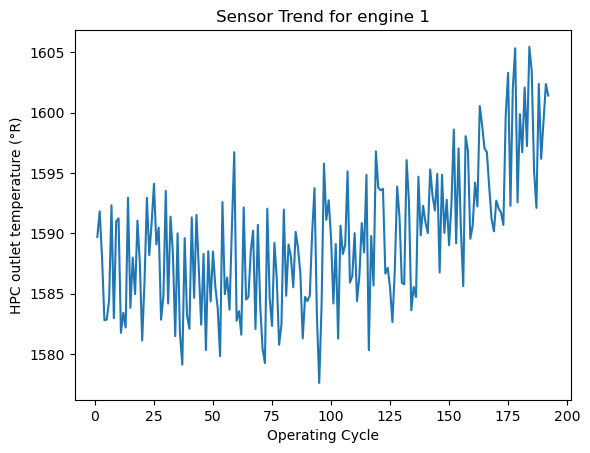

In [29]:
plt.plot(engine_1["cycle"], engine_1["HPC outlet temperature (°R)"])
plt.xlabel("Operating Cycle")
plt.ylabel("HPC outlet temperature (°R)")
plt.title("Sensor Trend for engine 1")
plt.show()

In [30]:
engine_2 = df_clean[df_clean["engine"]==2]

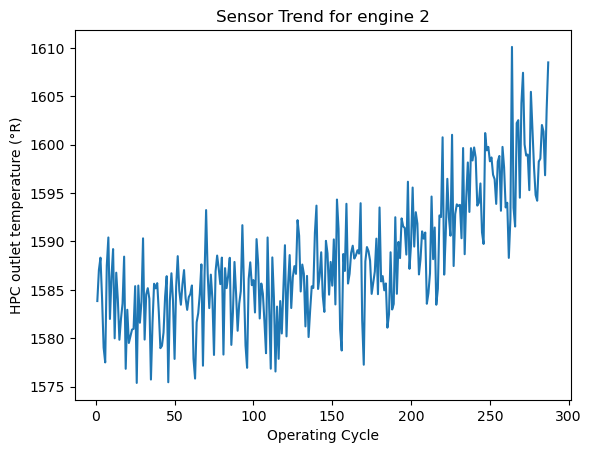

In [31]:
plt.plot(engine_2["cycle"], engine_2["HPC outlet temperature (°R)"])
plt.xlabel("Operating Cycle")
plt.ylabel("HPC outlet temperature (°R)")
plt.title("Sensor Trend for engine 2")
plt.show()

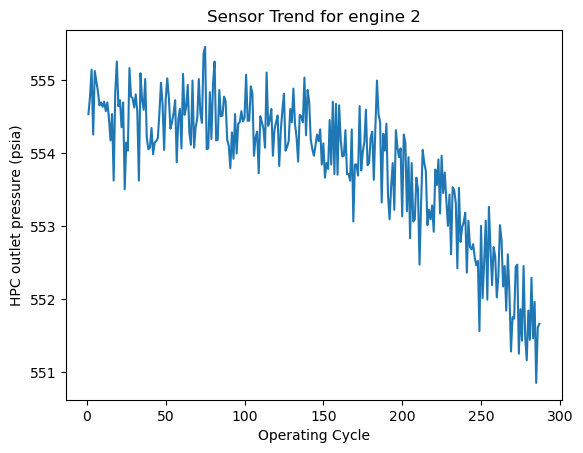

In [32]:
plt.plot(engine_2["cycle"], engine_2["HPC outlet pressure (psia)"])
plt.xlabel("Operating Cycle")
plt.ylabel("HPC outlet pressure (psia)")
plt.title("Sensor Trend for engine 2")
plt.show()

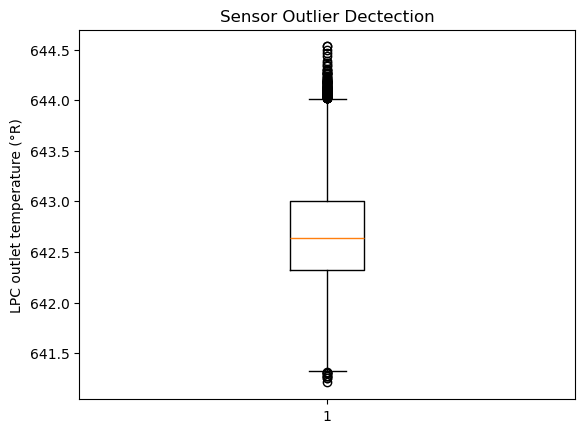

In [33]:
plt.boxplot(df[sensor].dropna())
plt.ylabel(sensor)
plt.title("Sensor Outlier Dectection")
plt.show()

In [34]:
Q1 = df[sensor].quantile(0.25)
Q3 = df[sensor].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit  = Q3 + 1.5 * IQR
print("Q1:", Q1)
print("Q2:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("upper limit:", upper_limit)

Q1: 642.325
Q2: 643.0
IQR: 0.6749999999999545
Lower Limit: 641.3125000000001
upper limit: 644.0124999999999


In [35]:
correlation = df_clean.corr(numeric_only = True)

In [36]:
correlation["RUL"].sort_values()

cycle                                   -0.736241
HPC outlet Static pressure (psia)       -0.696228
LPT outlet temperature (°R)             -0.678948
Bypass Ratio                            -0.642667
LPC outlet temperature (°R)             -0.606484
Bleed Enthalpy                          -0.606154
HPC outlet temperature (°R)             -0.584520
Physical fan speed (rpm)                -0.563968
Corrected fan speed (rpm)               -0.562569
Physical core speed (rpm)               -0.390102
Corrected core speed (rpm)              -0.306769
op_setting_1                            -0.003198
op_setting_2                            -0.001948
engine                                   0.078753
High-pressure turbines Cool air flow     0.629428
Low-pressure turbines Cool air flow      0.635662
HPC outlet pressure (psia)               0.657223
Ratio of fuel flow to Ps30 (pps/psia)    0.671983
RUL                                      1.000000
Name: RUL, dtype: float64

# Feature Engineering

In [37]:
df_clean.columns.tolist()

['engine',
 'cycle',
 'op_setting_1',
 'op_setting_2',
 'LPC outlet temperature (°R)',
 'HPC outlet temperature (°R)',
 'LPT outlet temperature (°R)',
 'HPC outlet pressure (psia)',
 'Physical fan speed (rpm)',
 'Physical core speed (rpm)',
 'HPC outlet Static pressure (psia)',
 'Ratio of fuel flow to Ps30 (pps/psia)',
 'Corrected fan speed (rpm)',
 'Corrected core speed (rpm)',
 'Bypass Ratio',
 'Bleed Enthalpy',
 'High-pressure turbines Cool air flow',
 'Low-pressure turbines Cool air flow',
 'RUL']

In [38]:
sensor_columns = [
 "LPC outlet temperature (°R)",  
 "HPC outlet temperature (°R)"]
sensor_data = df_clean[sensor_columns].copy()
sensor_data.head()

,LPC outlet temperature (°R),HPC outlet temperature (°R)
0,641.82,1589.70
1,642.15,1591.82
2,642.35,1587.99
3,642.35,1582.79
4,642.37,1582.85


# temp_diff = HPC outlet temp. - LPC outlet temp.

In [39]:
sensor_data["temperature_difference"] = (
    sensor_data["HPC outlet temperature (°R)"] - sensor_data["LPC outlet temperature (°R)"]
)
sensor_data.head()

,LPC outlet temperature (°R),HPC outlet temperature (°R),temperature_difference
0,641.82,1589.70,947.88
1,642.15,1591.82,949.67
2,642.35,1587.99,945.64
3,642.35,1582.79,940.44
4,642.37,1582.85,940.48


In [40]:
df_clean["temperature_difference"] = (
    df_clean["HPC outlet temperature (°R)"] - df_clean["LPC outlet temperature (°R)"]
)
df_clean[[
 "LPC outlet temperature (°R)",  
 "HPC outlet temperature (°R)",
 "temperature_difference"]].head()

,LPC outlet temperature (°R),HPC outlet temperature (°R),temperature_difference
0,641.82,1589.70,947.88
1,642.15,1591.82,949.67
2,642.35,1587.99,945.64
3,642.35,1582.79,940.44
4,642.37,1582.85,940.48


In [41]:
df_clean["HPC_temperature_rolling_mean"] = df_clean.groupby("engine")["HPC outlet temperature (°R)"].transform(lambda x: x.rolling(window=3).mean())
df_clean[["engine","cycle","HPC outlet temperature (°R)", "HPC_temperature_rolling_mean"]].head(10)

,engine,cycle,HPC outlet temperature (°R),HPC_temperature_rolling_mean
0,1,1,1589.70,NaN
1,1,2,1591.82,NaN
2,1,3,1587.99,1589.836667
3,1,4,1582.79,1587.533333
4,1,5,1582.85,1584.543333
5,1,6,1584.47,1583.370000
6,1,7,1592.32,1586.546667
7,1,8,1582.96,1586.583333
8,1,9,1590.98,1588.753333
9,1,10,1591.24,1588.393333


In [42]:
df_clean["HPC_temperature_rolling_mean"].isnull().sum()

np.int64(200)

In [43]:
df_clean = df_clean.dropna(subset=["HPC_temperature_rolling_mean"])
df_clean.head(10)

,engine,cycle,op_setting_1,op_setting_2,LPC outlet temperature (°R),HPC outlet temperature (°R),LPT outlet temperature (°R),HPC outlet pressure (psia),Physical fan speed (rpm),Physical core speed (rpm),...,Ratio of fuel flow to Ps30 (pps/psia),Corrected fan speed (rpm),Corrected core speed (rpm),Bypass Ratio,Bleed Enthalpy,High-pressure turbines Cool air flow,Low-pressure turbines Cool air flow,RUL,temperature_difference,HPC_temperature_rolling_mean
2,1,3,-0.0043,0.0003,642.35,1587.99,1404.20,554.26,2388.08,9052.94,...,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442,189,945.64,1589.836667
3,1,4,0.0007,0.0000,642.35,1582.79,1401.87,554.45,2388.11,9049.48,...,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739,188,940.44,1587.533333
4,1,5,-0.0019,-0.0002,642.37,1582.85,1406.22,554.00,2388.06,9055.15,...,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044,187,940.48,1584.543333
5,1,6,-0.0043,-0.0001,642.10,1584.47,1398.37,554.67,2388.02,9049.68,...,521.68,2388.03,8132.85,8.4108,391,38.98,23.3669,186,942.37,1583.370000
6,1,7,0.0010,0.0001,642.48,1592.32,1397.77,554.34,2388.02,9059.13,...,522.32,2388.03,8132.32,8.3974,392,39.10,23.3774,185,949.84,1586.546667
7,1,8,-0.0034,0.0003,642.56,1582.96,1400.97,553.85,2388.00,9040.80,...,522.47,2388.03,8131.07,8.4076,391,38.97,23.3106,184,940.40,1586.583333
8,1,9,0.0008,0.0001,642.12,1590.98,1394.80,553.69,2388.05,9046.46,...,521.79,2388.05,8125.69,8.3728,392,39.05,23.4066,183,948.86,1588.753333
9,1,10,-0.0033,0.0001,641.71,1591.24,1400.46,553.59,2388.05,9051.70,...,521.79,2388.06,8129.38,8.4286,393,38.95,23.4694,182,949.53,1588.393333
10,1,11,0.0018,-0.0003,642.28,1581.75,1400.64,554.54,2388.05,9049.61,...,521.40,2388.01,8140.58,8.4340,392,38.94,23.4787,181,939.47,1587.990000
11,1,12,0.0016,0.0002,642.06,1583.41,1400.15,554.52,2388.09,9049.37,...,521.80,2388.02,8134.25,8.3938,391,39.06,23.3660,180,941.35,1585.466667


In [44]:
df_clean[["engine","cycle","temperature_difference","HPC_temperature_rolling_mean"]].head()

,engine,cycle,temperature_difference,HPC_temperature_rolling_mean
2,1,3,945.64,1589.836667
3,1,4,940.44,1587.533333
4,1,5,940.48,1584.543333
5,1,6,942.37,1583.370000
6,1,7,949.84,1586.546667


In [45]:
correlation = df_clean.corr(numeric_only =True)

In [46]:
rul_correlation = correlation["RUL"].sort_values(ascending = False)
rul_correlation

RUL                                      1.000000
Ratio of fuel flow to Ps30 (pps/psia)    0.672935
HPC outlet pressure (psia)               0.657943
Low-pressure turbines Cool air flow      0.636306
High-pressure turbines Cool air flow     0.630257
engine                                   0.079551
op_setting_2                            -0.000995
op_setting_1                            -0.003401
Corrected core speed (rpm)              -0.306370
Physical core speed (rpm)               -0.389887
temperature_difference                  -0.562304
Corrected fan speed (rpm)               -0.563524
Physical fan speed (rpm)                -0.565297
HPC outlet temperature (°R)             -0.585377
Bleed Enthalpy                          -0.606680
LPC outlet temperature (°R)             -0.606686
Bypass Ratio                            -0.643740
LPT outlet temperature (°R)             -0.679622
HPC_temperature_rolling_mean            -0.687265
HPC outlet Static pressure (psia)       -0.697184


In [47]:
features = [
    "cycle",
    "LPC outlet temperature (°R)",
    "HPC outlet temperature (°R)",
    "temperature_difference",
    "HPC_temperature_rolling_mean"
]
X = df_clean[features].copy()
X.head()

,cycle,LPC outlet temperature (°R),HPC outlet temperature (°R),temperature_difference,HPC_temperature_rolling_mean
2,3,642.35,1587.99,945.64,1589.836667
3,4,642.35,1582.79,940.44,1587.533333
4,5,642.37,1582.85,940.48,1584.543333
5,6,642.10,1584.47,942.37,1583.370000
6,7,642.48,1592.32,949.84,1586.546667


In [48]:
X.describe()

,cycle,LPC outlet temperature (°R),HPC outlet temperature (°R),temperature_difference,HPC_temperature_rolling_mean
count,20431.000000,20431.00000,20431.000000,20431.000000,20431.000000
mean,109.858304,642.68395,1590.559709,947.875758,1590.483913
std,68.390102,0.50036,6.132379,5.844159,5.128087
min,3.000000,641.21000,1571.040000,928.370000,1574.393333
25%,54.000000,642.33000,1586.310000,943.830000,1586.813333
50%,105.000000,642.65000,1590.140000,947.520000,1589.896667
75%,157.000000,643.01000,1594.420000,951.570000,1593.533333
max,362.000000,644.53000,1616.910000,973.560000,1610.396667


In [49]:
from sklearn.preprocessing import StandardScaler

In [50]:
scaler = StandardScaler()

In [51]:
X_scaled = scaler.fit_transform(X)
X_scaled[:5]

array([[-1.56252025, -0.66743646, -0.41904972, -0.38257225, -0.12621913],
       [-1.54789789, -0.66743646, -1.2670285 , -1.27237129, -0.57539047],
       [-1.53327554, -0.62746427, -1.25724413, -1.26552668, -1.15846817],
       [-1.51865318, -1.1670889 , -0.99306612, -0.94211895, -1.38727905],
       [-1.50403082, -0.4076172 ,  0.28705569,  0.33611159, -0.76779961]])

In [52]:
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
)
X_scaled_df.head()

,cycle,LPC outlet temperature (°R),HPC outlet temperature (°R),temperature_difference,HPC_temperature_rolling_mean
2,-1.562520,-0.667436,-0.419050,-0.382572,-0.126219
3,-1.547898,-0.667436,-1.267028,-1.272371,-0.575390
4,-1.533276,-0.627464,-1.257244,-1.265527,-1.158468
5,-1.518653,-1.167089,-0.993066,-0.942119,-1.387279
6,-1.504031,-0.407617,0.287056,0.336112,-0.767800


In [53]:
X_scaled_df.describe()

,cycle,LPC outlet temperature (°R),HPC outlet temperature (°R),temperature_difference,HPC_temperature_rolling_mean
count,2.043100e+04,2.043100e+04,2.043100e+04,2.043100e+04,2.043100e+04
mean,1.112886e-17,-3.424161e-13,1.485494e-14,2.545100e-14,1.337549e-14
std,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00,1.000024e+00
min,-1.562520e+00,-2.945852e+00,-3.183134e+00,-3.337732e+00,-3.137812e+00
25%,-8.167800e-01,-7.074087e-01,-6.930121e-01,-6.922908e-01,-7.157971e-01
50%,-7.103985e-02,-6.785354e-02,-6.844310e-02,-6.087567e-02,-1.145186e-01
75%,6.893227e-01,6.516460e-01,6.295087e-01,6.321409e-01,5.946651e-01
max,3.686906e+00,3.689533e+00,4.297017e+00,4.394964e+00,3.883171e+00


In [54]:
comparision = pd.DataFrame({
    "Original_HPC_Temperature":X["HPC outlet temperature (°R)"].head(10).values,
    "Scaled_HPC_Temperature":X_scaled_df["HPC outlet temperature (°R)"].head(10).values
})
comparision

,Original_HPC_Temperature,Scaled_HPC_Temperature
0,1587.99,-0.419050
1,1582.79,-1.267028
2,1582.85,-1.257244
3,1584.47,-0.993066
4,1592.32,0.287056
5,1582.96,-1.239306
6,1590.98,0.068538
7,1591.24,0.110937
8,1581.75,-1.436624
9,1583.41,-1.165923


# Training and Testing Data

In [55]:
features = [
    "cycle",
    "LPC outlet temperature (°R)",
    "HPC outlet temperature (°R)",
    "temperature_difference",
    "HPC_temperature_rolling_mean"
]
X = df_clean[features].copy()
X.head(10)

,cycle,LPC outlet temperature (°R),HPC outlet temperature (°R),temperature_difference,HPC_temperature_rolling_mean
2,3,642.35,1587.99,945.64,1589.836667
3,4,642.35,1582.79,940.44,1587.533333
4,5,642.37,1582.85,940.48,1584.543333
5,6,642.10,1584.47,942.37,1583.370000
6,7,642.48,1592.32,949.84,1586.546667
7,8,642.56,1582.96,940.40,1586.583333
8,9,642.12,1590.98,948.86,1588.753333
9,10,641.71,1591.24,949.53,1588.393333
10,11,642.28,1581.75,939.47,1587.990000
11,12,642.06,1583.41,941.35,1585.466667


In [56]:
y = df_clean["RUL"].copy()

In [57]:
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

X shape: (20431, 5)
y shape: (20431,)


In [58]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [59]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (16344, 5)
X_test shape: (4087, 5)
y_train shape: (16344,)
y_test shape: (4087,)


In [60]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [61]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [62]:
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=features,
    index=X_train.index
)
X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=features,
    index=X_test.index
)

In [63]:
X_train_scaled_df.head()

,cycle,LPC outlet temperature (°R),HPC outlet temperature (°R),temperature_difference,HPC_temperature_rolling_mean
17733,0.095550,0.496193,0.194317,0.161363,0.182566
2065,0.622958,1.137505,-0.290022,-0.401713,-0.760387
6449,-1.047168,-2.169262,-0.165665,0.012010,-0.315573
4620,-0.783464,0.556316,-1.000167,-1.096974,-0.488556
15269,0.022299,1.097423,0.434850,0.362216,-0.186161


In [64]:
X_test_scaled_df.head()

,cycle,LPC outlet temperature (°R),HPC outlet temperature (°R),temperature_difference,HPC_temperature_rolling_mean
19823,2.380985,0.556316,-0.802178,-0.889254,-0.011877
16387,-1.457374,-2.229385,-1.566320,-1.452330,-1.923147
7726,-0.300006,0.255701,0.369399,0.365649,0.324985
1416,0.051599,-0.245325,-1.590864,-1.648033,-1.398994
1342,-1.032517,-0.586022,-1.345422,-1.361345,-0.899554


# Prediction

In [65]:
from sklearn.linear_model import LinearRegression

In [66]:
model =LinearRegression()

In [67]:
model.fit(X_train_scaled_df, y_train)

LinearRegression()

In [68]:
y_pred = model.predict(X_test_scaled_df)

In [69]:
print("Predicted RUL values:")
print(y_pred[:10])

Predicted RUL values:
[ 25.78235849 214.18124165 107.68608627 135.36420337 164.10611851
 104.84339403 182.30648988  48.75292485 145.798456    49.39231556]


In [70]:
comparision = pd.DataFrame({
    "Actual RUL": y_test.values,
    "Predicted RUL": y_pred
})
comparision.head(10)

,Actual RUL,Predicted RUL
0,64,25.782358
1,204,214.181242
2,99,107.686086
3,146,135.364203
4,220,164.106119
5,114,104.843394
6,209,182.306490
7,34,48.752925
8,136,145.798456
9,117,49.392316


In [71]:
print("Actual RUL shape:", y_test.shape)
print("Predicted RUL shape:", y_pred.shape)

Actual RUL shape: (4087,)
Predicted RUL shape: (4087,)


# Model Evaluation

In [72]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [73]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Linear Regression MAE: {mae:.2f} cycles")
print(f"Linear Regression RMSE: {rmse:.2f} cycles")
print(f"Linear Regression R2 Score: {r2:.2f}")

Linear Regression MAE: 31.21 cycles
Linear Regression RMSE: 40.64 cycles
Linear Regression R2 Score: 0.63


In [74]:
from sklearn.ensemble import RandomForestRegressor

In [75]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

In [76]:
rf_model.fit(X_train_scaled_df, y_train)

RandomForestRegressor(random_state=42)

In [77]:
y_pred_rf = rf_model.predict(X_test_scaled_df)

In [78]:
print("RF Predicted RUL value:")
print(y_pred_rf[:10])

RF Predicted RUL value:
[ 83.13 225.37 104.51 127.55 176.3   73.71 195.81  41.49 131.13  81.05]


In [79]:
comparision_rf = pd.DataFrame({
    "Actual RUL":y_test.values,
    "RF Predicted RUL":y_pred_rf
})
comparision_rf.head(10)

,Actual RUL,RF Predicted RUL
0,64,83.13
1,204,225.37
2,99,104.51
3,146,127.55
4,220,176.30
5,114,73.71
6,209,195.81
7,34,41.49
8,136,131.13
9,117,81.05


In [80]:
mae = mean_absolute_error(y_test, y_pred_rf)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2 = r2_score(y_test, y_pred_rf)

print(f"Random Forest MAE: {mae:.2f} cycles")
print(f"Random Forest RMSE: {rmse:.2f} cycles")
print(f"Random Forest R2 Score: {r2:.2f}")

Random Forest MAE: 28.29 cycles
Random Forest RMSE: 38.71 cycles
Random Forest R2 Score: 0.67


# Dashboard

In [81]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ipywidgets as widgets
from ipywidgets import interact

In [82]:
viz_df = pd.DataFrame({
    "engine": df_clean.loc[X_test.index, "engine"],
    "cycle": df_clean.loc[X_test.index, "cycle"],
    "Actual_RUL": y_test,
    "Predicted_RUL": y_pred_rf,
}).sort_values(by=["engine", "cycle"])

In [83]:
def plot_engine_predictions(engine_id):
    engine_data = viz_df[viz_df["engine"] == engine_id]
    plt.figure(figsize=(10, 5))
    plt.plot(
        engine_data["cycle"],
        engine_data["Actual_RUL"],
        label="Actual RUL (True Clock)",
        color="#1f77b4",
        linewidth=2.5,
    )
    plt.plot(
        engine_data["cycle"],
        engine_data["Predicted_RUL"],
        label="Random Forest Prediction",
        color="#d62728",
        linestyle="--",
        alpha=0.8,
        linewidth=2,
    )
    plt.xlabel("Operational Cycle (Flights)", fontsize=12)
    plt.ylabel("Remaining Useful Life (RUL)", fontsize=12)
    plt.title(
        f"Live Telemetry Breakdown: Engine ID {engine_id}",
        fontsize=14,
        fontweight="bold",
    )
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(fontsize=11, loc="upper right")
    plt.axhspan(0, 30, color="red", alpha=0.1, label="Critical Maintenance Window")
    plt.show()
engine_options = sorted(viz_df["engine"].unique())
interact(
    plot_engine_predictions,
    engine_id=widgets.Dropdown(
        options=engine_options,
        value=engine_options[0],
        description="Select Engine:",
        disabled=False,
    )
)

interactive(children=(Dropdown(description='Select Engine:', options=(np.int64(1), np.int64(2), np.int64(3), n…

<function __main__.plot_engine_predictions(engine_id)>